# Figure S3 — Epistasis on a linear scale

Figs 2 and 3 measure departures from additivity in log counts (multiplicative effects on counts). Here the same
knockout predictions are converted to counts (expm1) and the departure from additivity is expressed as a fraction of
the intact peak's predicted counts:
- **direct vs other motifs** (`pipeline/03_epistasis`): (wt − none − (p0_only − none) − (non_only − none)) / wt,
  over peaks with both direct and other motifs
- **direct sites** (`pipeline/04_direct_sites`, merged sites, native peak): (KO_all + Σᵢ (ref − KOᵢ) − ref) / ref,
  over peaks with ≥ 2 direct sites

Synergy: fraction of peaks with a value ≥ t; redundancy: ≤ −t. One curve per TF (mean over its experiments).
Inputs: `data/epi_curves_linear_{pos,neg}.parquet`, `data/self_epistasis_merged_direct_calc_wt_linear_{pos,neg}.parquet`
(`pipeline/05_curves/build_curves.py linear`). No GPU needed.

In [1]:
import sys
sys.path.insert(0, '../modules')        # run from notebooks/
import paths                            # data root, genome, repo locations (env BPNET_DATA, MISHA_HG38)
from plot_setup import fig_path         # editable PDF text; figures/ in the repository
%config InlineBackend.figure_format = 'retina'

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from curves import per_tf, plot_epi_curves, HIGHLIGHT

SIDE = {'pos': ('synergy (interaction ≥ t)', 'fraction of peaks with epistasis ≥ t'),
        'neg': ('redundancy (interaction ≤ −t)', 'fraction of peaks with epistasis ≤ −t')}
FILE_SIDE = {'pos': 'positive', 'neg': 'negative'}

## Direct vs other motifs

pos 1480 experiments, 538 TFs


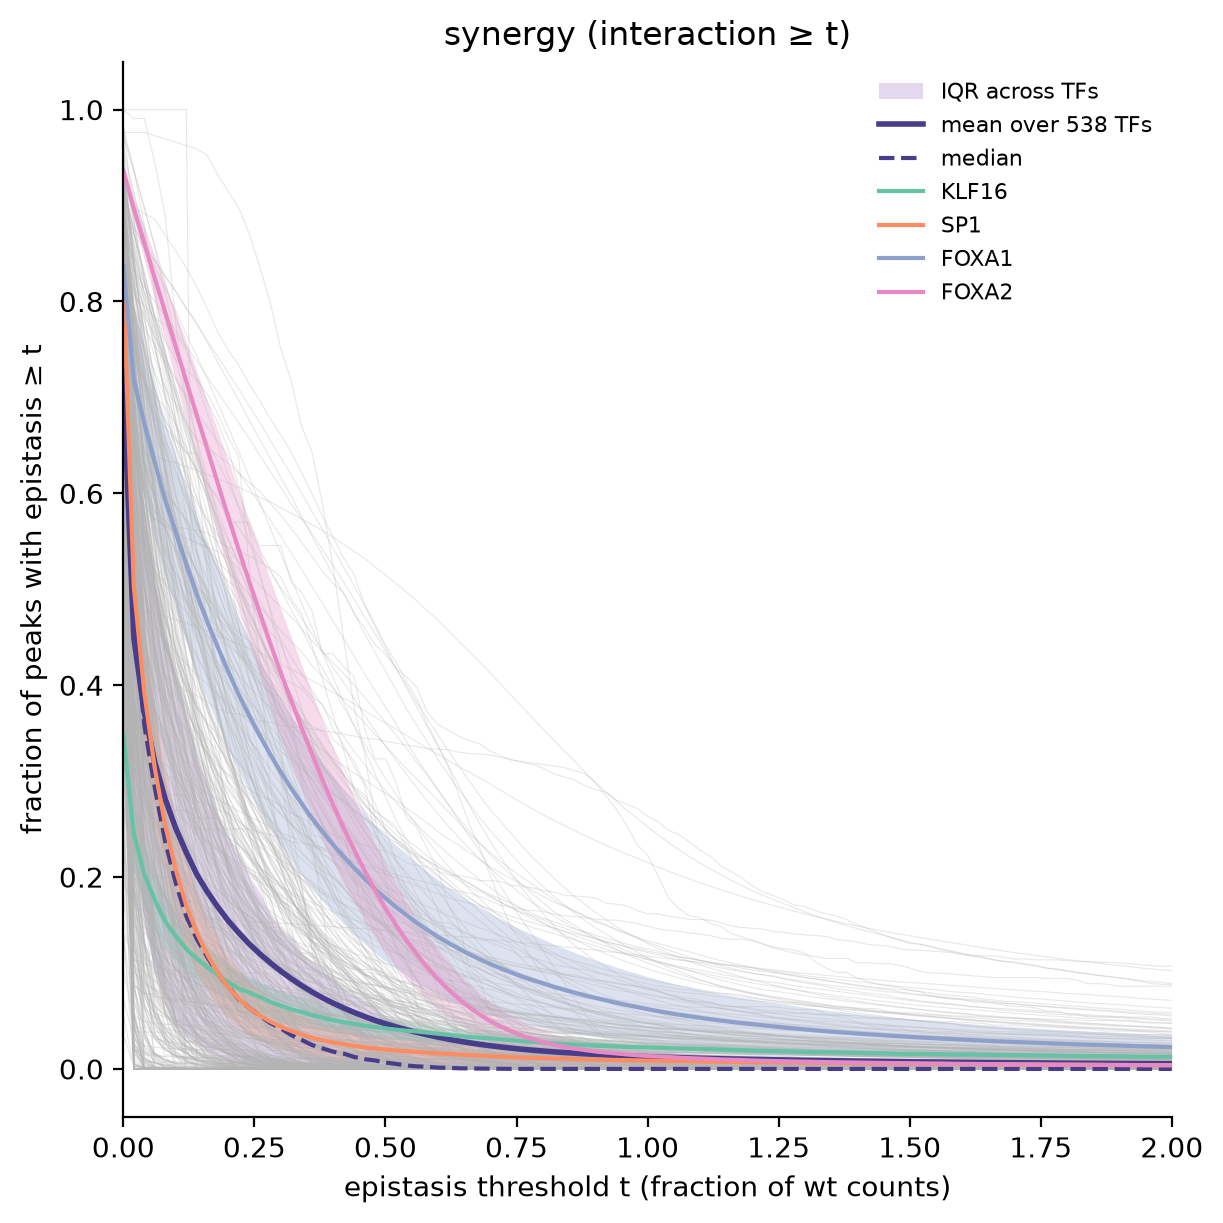

neg 1480 experiments, 538 TFs


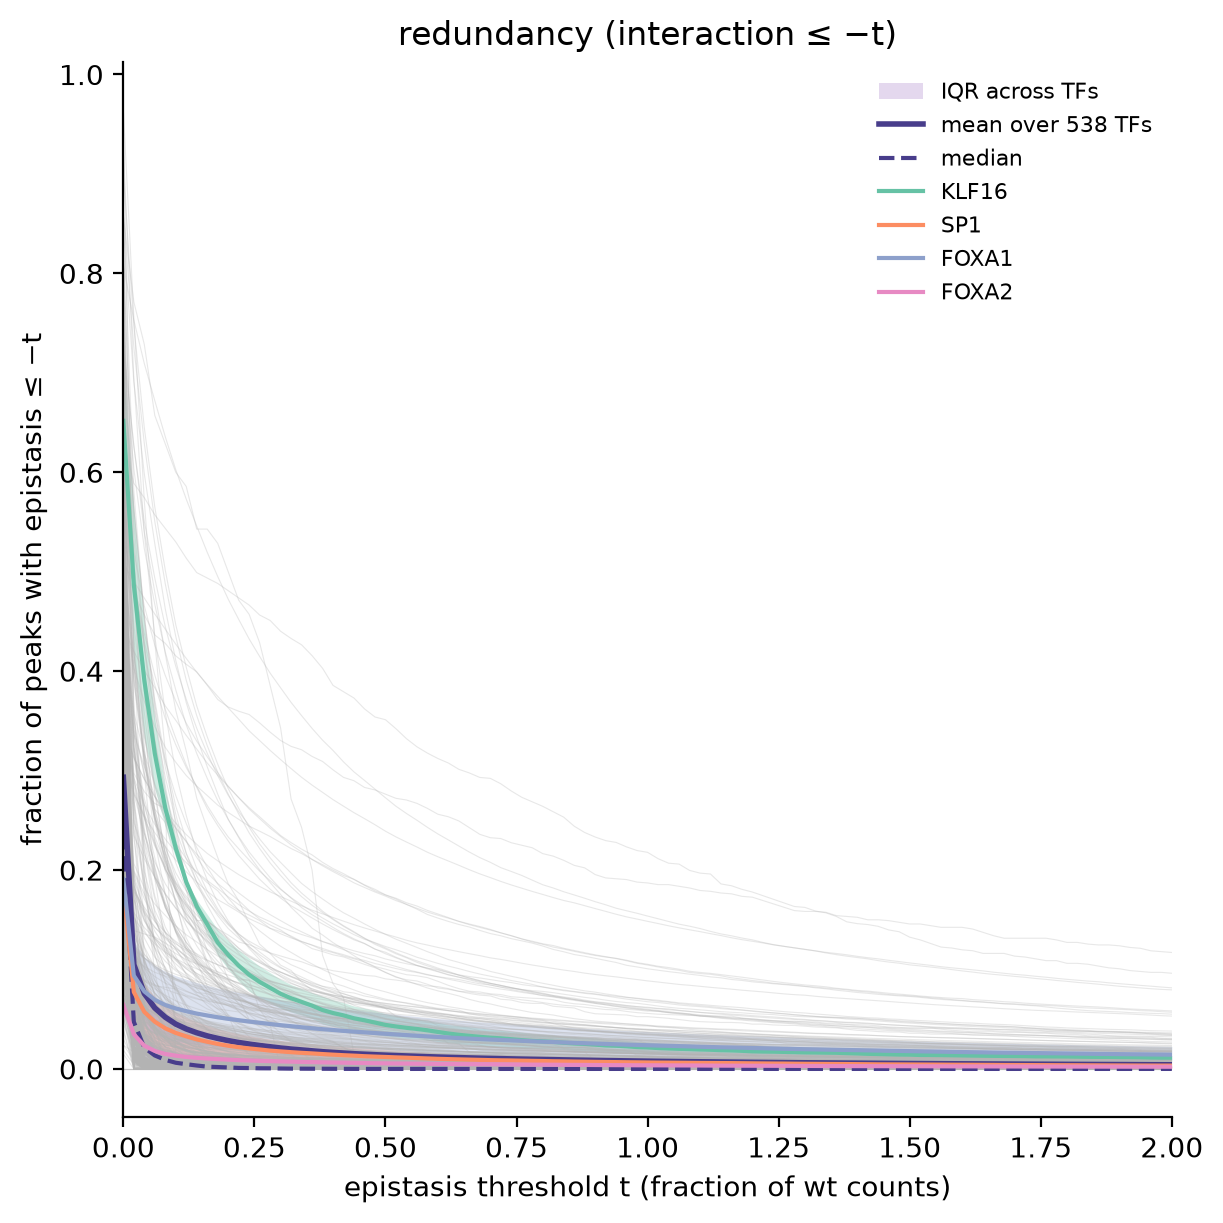

In [3]:
for side, (title, ylabel) in SIDE.items():
    curves = pd.read_parquet(paths.DATA / f'epi_curves_linear_{side}.parquet')
    mean, sem = per_tf(curves)
    print(side, len(curves), 'experiments,', len(mean), 'TFs')
    fig, ax = plt.subplots(1, figsize=(6, 6), constrained_layout=True)
    plot_epi_curves(mean, ax=ax, logy=False, sem=sem, highlight=HIGHLIGHT, show_mean=True, ylabel=ylabel,
                    xlabel='epistasis threshold t (fraction of wt counts)')
    ax.set_title(title)
    plt.show()
    fig.savefig(fig_path(f'epistasis_direct_others_linear_{FILE_SIDE[side]}.pdf'))

## Direct sites of a peak

pos 1506 experiments, 531 TFs


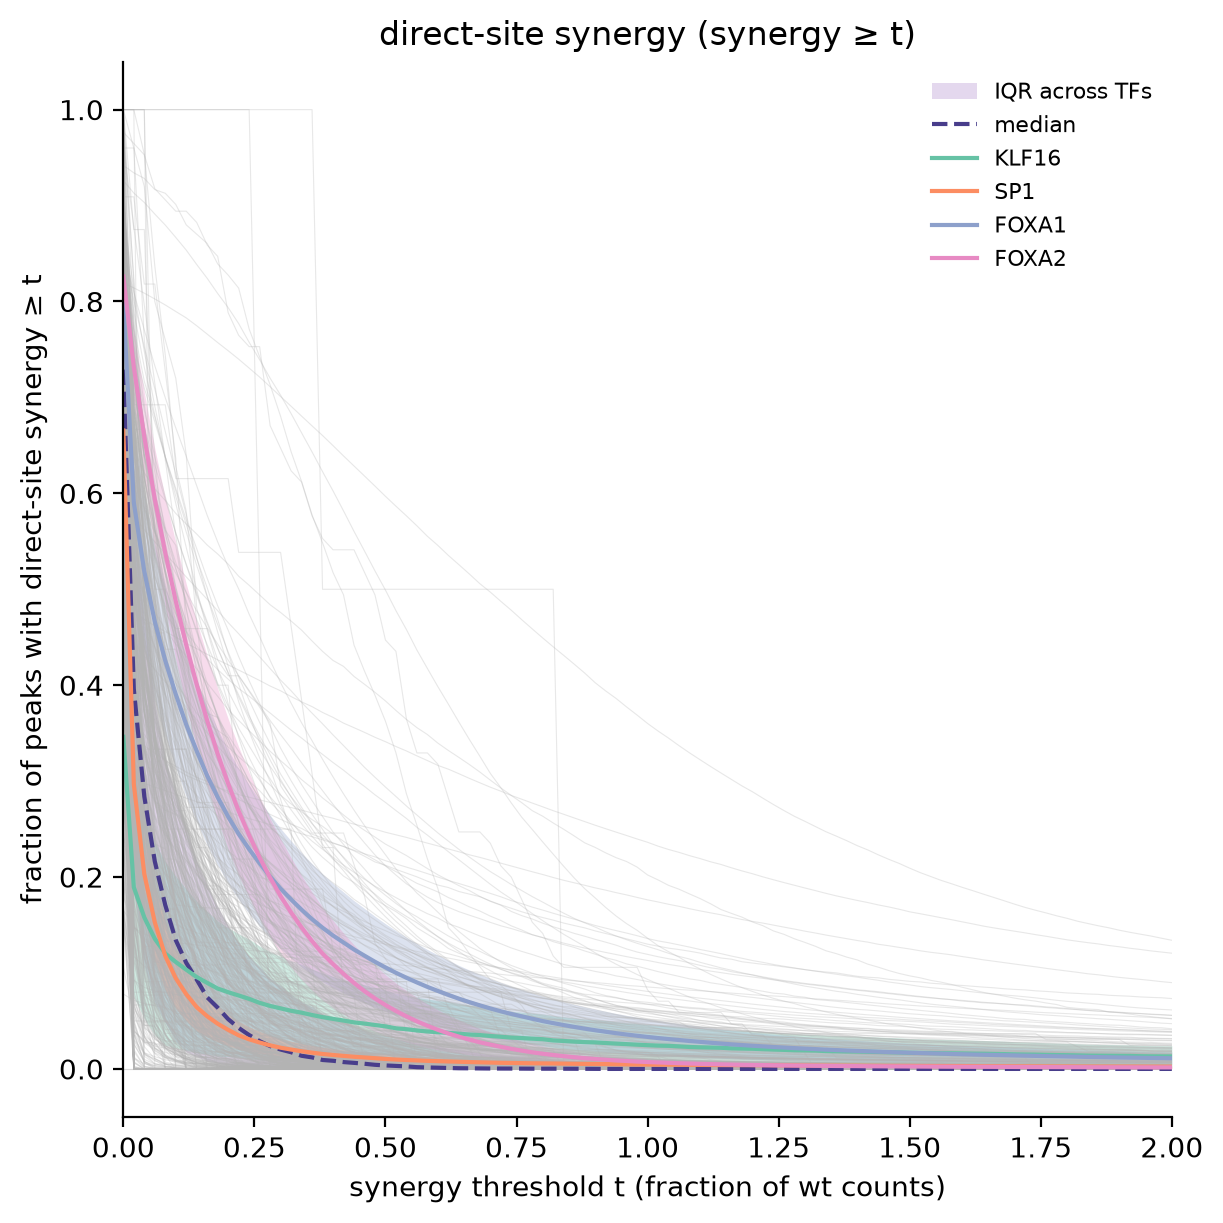

neg 1506 experiments, 531 TFs


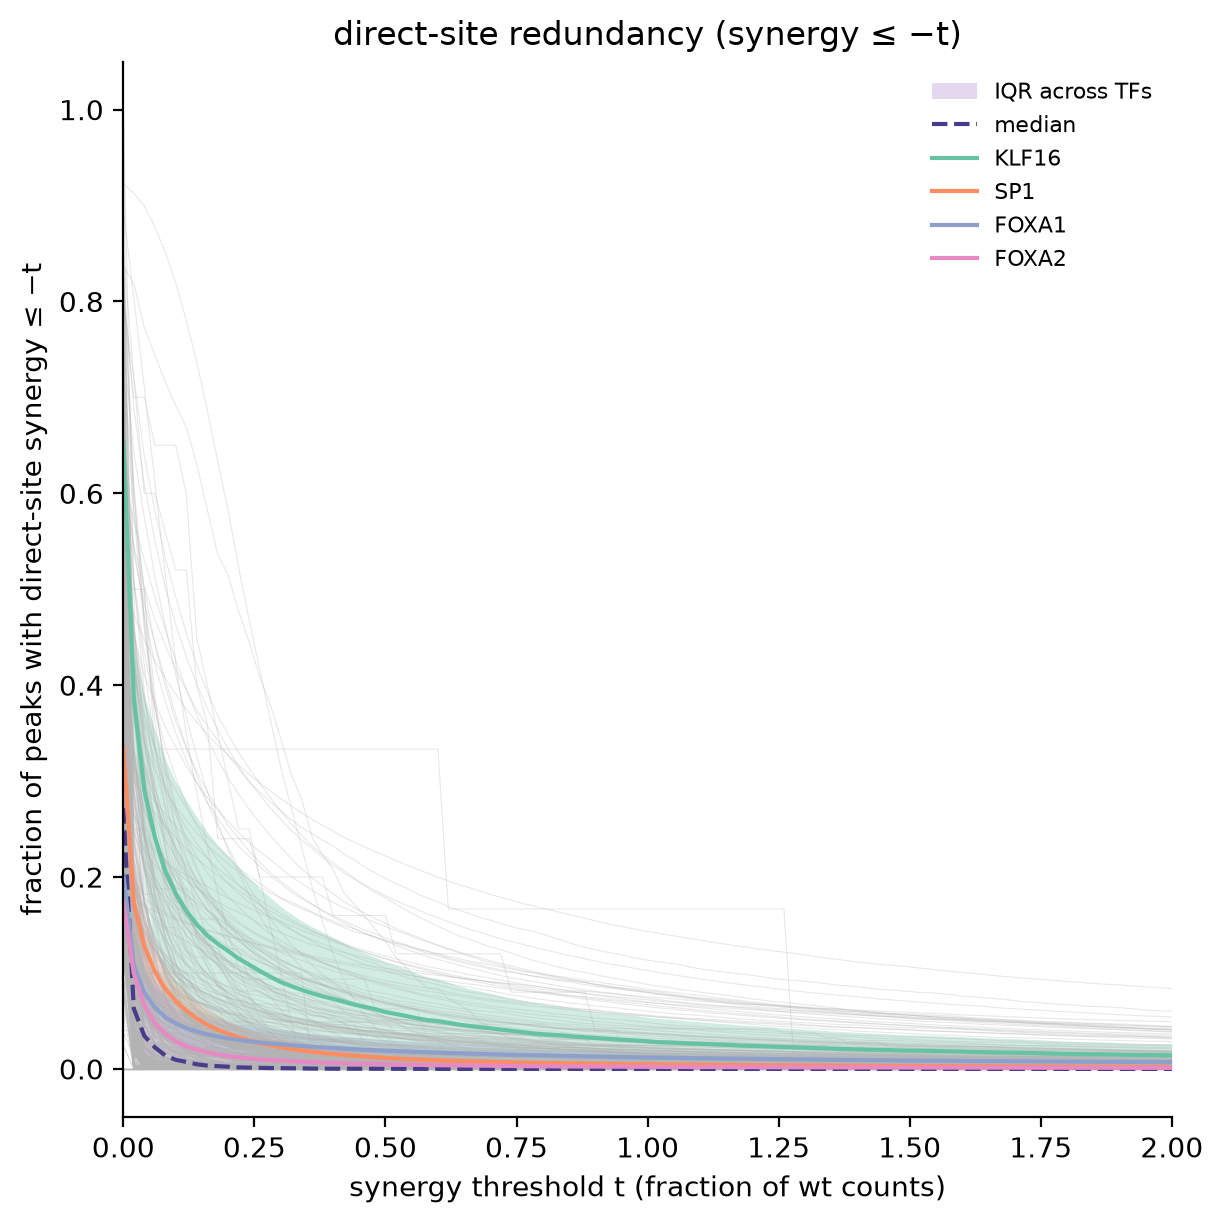

In [4]:
for side, (title, ylabel) in SIDE.items():
    curves = pd.read_parquet(paths.DATA / f'self_epistasis_merged_direct_calc_wt_linear_{side}.parquet')
    mean, sem = per_tf(curves)
    print(side, len(curves), 'experiments,', len(mean), 'TFs')
    fig, ax = plt.subplots(1, figsize=(6, 6), constrained_layout=True)
    plot_epi_curves(mean, ax=ax, logy=False, sem=sem, highlight=HIGHLIGHT,
                    ylabel=ylabel.replace('epistasis', 'direct-site synergy'),
                    xlabel='synergy threshold t (fraction of wt counts)')
    ax.set_title('direct-site ' + title.replace('interaction', 'synergy'))
    plt.show()
    fig.savefig(fig_path(f'epistasis_direct_direct_linear_{FILE_SIDE[side]}.pdf'))